# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 01
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | Intelligent Agent and PEAS | 25 |
| Q2 | BFS, DFS and Greedy Best-First | 30 |
| Q3 | Iris k-NN classification | 35 |
| Q4 | Viva: agent, PEAS, heuristics, k-NN, scaling | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Source:** `AI_MLQuestionList.pdf` (uploaded exam sheet), pages 1; background concepts from the supplied ICT-4202 laboratory manual. The source questions govern specifications; where a question leaves a parameter open, our choice is explicitly labeled.

**Quick access - one file per numbered question:** [Q1 / A](Set_01_A.py) | [Q2 / B](Set_01_B.py) | [Q3 / C](Set_01_C.py) | [Q4 / D: Viva practice](Set_01_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. Intelligent Agent and PEAS (25 marks)
**Question specification**  
Two-room vacuum world: A starts **Dirty**, B **Clean**, agent starts at **B**. Implement `Suck`, `Left`, `Right` and `NoOp`, stop when both rooms are clean, and display every percept-action pair. Also give PEAS for an autonomous office-document delivery robot.

### Theory and mathematical background
An **agent** senses the environment and selects an **action** from the current percept. A simple reflex rule depends on the current percept only; the rule `Dirty → Suck` is a condition-action rule.

A two-room agent that **stops when every room is clean** needs information beyond a purely local percept (either global sensing or internal state). Therefore the terminating variant is *reflex-style cleaning with global-state access*, not a strictly percept-only reflex agent.

Let $s_t$ denote the current environment and $a_t$ the selected action. A policy chooses $a_t=\pi(s_t)$, and the transition is $s_{t+1}=T(s_t,a_t)$. For the cleaning goal:
$$\text{NoOp when }\bigwedge_{r\in\mathcal{R}}\operatorname{Clean}(r).$$

**PEAS** describes Performance, Environment, Actuators, and Sensors.

### Algorithm / procedure
1. Inspect the current room and status. 2. Return `NoOp` if the entire world is clean. 3. Otherwise clean the current room if dirty; else move to the dirty room. 4. Update state and print the trace.

In [4]:
def vacuum_policy(location, rooms):
    if all(status == 'Clean' for status in rooms.values()):
        return 'NoOp'
    if rooms[location] == 'Dirty':
        return 'Suck'
    return 'Left' if location == 'B' else 'Right'

rooms = {'A': 'Dirty', 'B': 'Clean'}
location = 'B'
trace = []
for step in range(1, 12):
    percept = (location, rooms[location])
    action = vacuum_policy(location, rooms)
    trace.append((step, percept, action, dict(rooms)))
    print(f'Step {step}: percept={percept}, action={action}, rooms(before)={rooms}')
    if action == 'NoOp': break
    if action == 'Suck': rooms[location] = 'Clean'
    elif action == 'Left': location = 'A'
    elif action == 'Right': location = 'B'
print('Final environment:', rooms)
assert all(v == 'Clean' for v in rooms.values())
assert trace[-1][2] == 'NoOp'


Step 1: percept=('B', 'Clean'), action=Left, rooms(before)={'A': 'Dirty', 'B': 'Clean'}
Step 2: percept=('A', 'Dirty'), action=Suck, rooms(before)={'A': 'Dirty', 'B': 'Clean'}
Step 3: percept=('A', 'Clean'), action=NoOp, rooms(before)={'A': 'Clean', 'B': 'Clean'}
Final environment: {'A': 'Clean', 'B': 'Clean'}


### PEAS — autonomous university document-delivery robot
| Component | Description |
|:--|:--|
| **Performance** | Correct deliveries, timely service, minimal energy usage, safety, privacy, few collisions |
| **Environment** | Office rooms, corridors, stairs/elevators, doors, staff, obstacles, changing pedestrian traffic |
| **Actuators** | Wheel motors, steering/brakes, robotic gripper/document locker, audio/display notifications |
| **Sensors** | Camera, lidar/ultrasonic, wheel odometry, inertial sensor, proximity and door sensors, map/location data |

**Important distinction:** In a strict simple-reflex agent, the percept is only *(current room, current cleanliness)*. Knowing *all rooms are clean* requires a wider percept or internal memory. This solution follows the question's stop requirement with observable global room states.

---
## Q2. BFS, DFS and Greedy Best-First Search (30 marks)
**Question specification**  
`A:{B,C}, B:{D,E}, C:{F}, D:{G}, E:{G}, F:{G}, G:{}`. Implement BFS, DFS, Greedy using `h(A..G)=(6,4,3,2,2,1,0)`. Show path and nodes expanded; compare.

### Theory and mathematical background
For an unweighted graph, **BFS** expands the shallowest frontier state first (FIFO queue), so it finds a minimum-edge path when each edge has equal cost. **DFS** explores a branch deeply first (LIFO stack), so its outcome depends on neighbor order. A **visited set** prevents re-expansion.

With $V$ vertices and $E$ edges, BFS and DFS can both run in $O(V+E)$ time on an adjacency-list graph; their frontier sizes and discovered-node storage differ. In tree-search notation, BFS typically uses $O(b^{d+1})$ space, while DFS uses $O(bm)$ space ($b$ branching factor, $d$ shallowest goal depth, $m$ maximum depth). These are different models of complexity.

Greedy prioritizes $h(n)$; unlike BFS in an unweighted graph it does not guarantee the shallowest solution in general.

In [5]:
from collections import deque

import heapq

from itertools import count

def bfs(graph, start, goal):
    queue = deque([(start, [start])])
    seen = {start}
    expanded = []
    while queue:
        node, path = queue.popleft()
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                seen.add(nxt)
                queue.append((nxt, path + [nxt]))
    return None, expanded

def dfs(graph, start, goal):
    stack = [(start, [start])]
    seen = set()
    expanded = []
    while stack:
        node, path = stack.pop()
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        # Reverse push order so the FIRST listed neighbor is explored first.
        for nxt in reversed(graph.get(node, [])):
            if nxt not in seen:
                stack.append((nxt, path + [nxt]))
    return None, expanded

def greedy_unweighted(graph, h, start, goal):
    tie = count()
    heap = [(h[start], next(tie), start, [start])]
    seen, expanded = set(), []
    while heap:
        _, _, node, path = heapq.heappop(heap)
        if node in seen: continue
        seen.add(node)
        expanded.append(node)
        if node == goal:
            return path, expanded
        for nxt in graph.get(node, []):
            if nxt not in seen:
                heapq.heappush(heap, (h[nxt], next(tie), nxt, path + [nxt]))
    return None, expanded

graph = {'A':['B','C'], 'B':['D','E'], 'C':['F'],
         'D':['G'], 'E':['G'], 'F':['G'], 'G':[]}
h = {'A':6,'B':4,'C':3,'D':2,'E':2,'F':1,'G':0}
for name, result in [('BFS', bfs(graph,'A','G')),
                     ('DFS', dfs(graph,'A','G')),
                     ('Greedy', greedy_unweighted(graph,h,'A','G'))]:
    path, expanded = result
    print(f'{name:7}: path={path} | expanded={expanded} | count={len(expanded)}')


BFS    : path=['A', 'B', 'D', 'G'] | expanded=['A', 'B', 'C', 'D', 'E', 'F', 'G'] | count=7
DFS    : path=['A', 'B', 'D', 'G'] | expanded=['A', 'B', 'D', 'G'] | count=4
Greedy : path=['A', 'C', 'F', 'G'] | expanded=['A', 'C', 'F', 'G'] | count=4


### Result interpretation and discussion
**Interpretation:** BFS expands in increasing path depth; DFS takes the first listed branch deeply, while Greedy uses the assigned heuristic values. Every listed expanded sequence **includes the goal when it is removed from the frontier**. Change the adjacency order or heuristic to see why expansion order is algorithm-dependent.

---
## Q3. Machine Learning — k-NN (35 marks)
**Question specification**  
Load Iris, stratified 70/30 train-test split with `random_state=42`; test $k=1,3,5,7$, identify the best test accuracy, print its confusion matrix, then standardize features and repeat that $k$.

### Theory and mathematical background
**k-Nearest Neighbors (k-NN)** predicts the majority label among the $k$ nearest training samples. A common distance is Euclidean:
$$d(\mathbf x,\mathbf z)=\sqrt{\sum_{j=1}^{p}(x_j-z_j)^2}.$$
Standardization rescales a feature using training-set statistics:
$$z_j=\frac{x_j-\mu_j^{\mathrm{train}}}{\sigma_j^{\mathrm{train}}}.$$
**Accuracy** $=(TP+TN)/(TP+TN+FP+FN)$ for binary labels (or total correct / total cases for multiclass). A confusion matrix $C_{ij}$ counts instances of actual class $i$ predicted as class $j$. Fit scaling on training samples only to prevent leakage.

Iris samples: (150, 4) | train: 105 | test: 45
Class order: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]
 k  test_accuracy
 1       0.933333
 3       0.955556
 5       0.977778
 7       0.955556
Best k on this fixed test split: 5
Confusion matrix (rows=true, columns=predicted):
 [[15  0  0]
 [ 0 15  0]
 [ 0  1 14]]
Unscaled accuracy: 0.9778
Scaled accuracy: 0.9111
Scaled confusion matrix:
 [[15  0  0]
 [ 0 15  0]
 [ 0  4 11]]


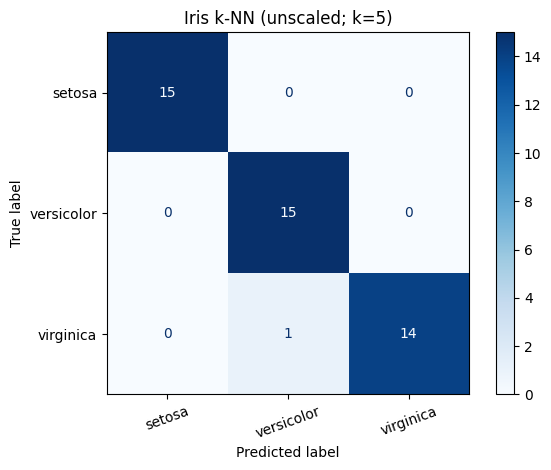

In [6]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
import pandas as pd
import numpy as np
iris = load_iris()
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30,
                                                    stratify=y, random_state=42)
print('Iris samples:', X.shape, '| train:', len(y_train), '| test:', len(y_test))
print('Class order:', list(iris.target_names))

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
results = []
models = {}
for k in [1,3,5,7]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    pred = m.predict(X_test)
    results.append({'k':k, 'test_accuracy':accuracy_score(y_test,pred)})
    models[k] = m
table = pd.DataFrame(results)
print(table.to_string(index=False))
best_k = sorted(results, key=lambda d: (-d['test_accuracy'],d['k']))[0]['k']
best_pred = models[best_k].predict(X_test)
print(f'Best k on this fixed test split: {best_k}')
print('Confusion matrix (rows=true, columns=predicted):\n', confusion_matrix(y_test,best_pred))
scaled_knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=best_k))
scaled_knn.fit(X_train, y_train)
scaled_pred = scaled_knn.predict(X_test)
print('Unscaled accuracy:', round(accuracy_score(y_test,best_pred),4))
print('Scaled accuracy:', round(accuracy_score(y_test,scaled_pred),4))
print('Scaled confusion matrix:\n', confusion_matrix(y_test,scaled_pred))
ConfusionMatrixDisplay.from_predictions(y_test, best_pred, display_labels=iris.target_names,
                                        cmap='Blues', xticks_rotation=20)
plt.title(f'Iris k-NN (unscaled; k={best_k})'); plt.tight_layout(); plt.show()


### Result interpretation and discussion
Standardization changes the relative influence of features when their numerical scales differ. Using a `Pipeline` ensures the scaler is fitted on training data only. **Coursework note:** Selecting the best $k$ directly on the test set follows the exam instruction, but in a real ML study, tune $k$ on a separate validation set or inner CV, reserving the test set for one final unbiased evaluation.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| What is an intelligent agent? | A system that perceives its environment and selects actions. |
| What does PEAS stand for? | Performance, Environment, Actuators, Sensors. |
| Why BFS uses a queue? | FIFO yields shallowest-first expansion in an unweighted graph. |
| How does Greedy select the next node? | It chooses minimum heuristic $h(n)$. |
| What is $k$ in k-NN? | Number of nearest training samples considered. |
| Why scale features? | So large-unit features do not automatically dominate distance. |
| What is a confusion matrix? | Counts of true versus predicted classes. |

| What is the main difference between BFS and DFS? | BFS uses a FIFO queue and explores level by level; DFS uses a stack or recursion and goes deep first. |
| What is a heuristic function? | h(n) estimates the remaining cost or distance from node n to the goal. |
| Give one PEAS example for a university delivery robot. | Performance: timely safe delivery; Environment: campus halls; Actuators: wheels and gripper; Sensors: camera and proximity sensor. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.